# Function 7 - Week 4: observation review

Review what the completed experiments have shown before using a model to choose
the next query. This notebook examines measured inputs and outputs; fitted
relationships, predictive uncertainty and candidate selection belong in
[model review and next query](model_predictions.ipynb).

The independent Week 4 `observations.csv` contains **30 initial observations
and three returned queries**, including the Week 3 return received on
**14 October 2026**. Larger signed outputs are better. The six input settings
each lie in `[0, 1)`. Earlier weekly notebooks remain the record of the evidence
and reasoning available at those times.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_7/Week_04 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish this week's evidence

Keep the supplied observations together as one initial batch. Their row order
does not describe a sequence of optimisation decisions. The three later rounds
each contain one deliberately selected query.

In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 7.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 30, 1: 1, 2: 1, 3: 1}:
    raise ValueError("This review expects the fixed Week 4 snapshot through round 3.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 4"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Weekly queries used: {len(returned)}/{TOTAL_QUERY_WEEKS}")

,Evidence,Count
0,Input dimensions,6
1,Initial observations,30
2,Returned queries,3
3,Total observations,33
4,"Queries available, including Week 4",10


Weekly queries used: 3/13


## 2. Place the latest return among the observed outputs

The latest output is **2.552418**, ranked **1/33 (1 = highest output)**.
It is the new incumbent, improving on round 2's **2.075222** by **0.477196 output
units**. All three returned queries exceed the initial best and are the three
highest observations.

In [3]:
print(output_review["report"])

Latest recorded submission: round 3 (1 new output).
Compared with 32 earlier observations (33 outputs in total).
Earlier output range: [0.00270146502451, 2.07522183931].

round-03: y = 2.55241765269 (positive); rank 1/33 (1 = highest output).
Inputs: x1 = 0.018718, x2 = 0.312926, x3 = 0.370268, x4 = 0.285721, x5 = 0.308321, x6 = 0.69567
New highest observed output. Largest absolute magnitude so far (1.23 times the earlier largest).


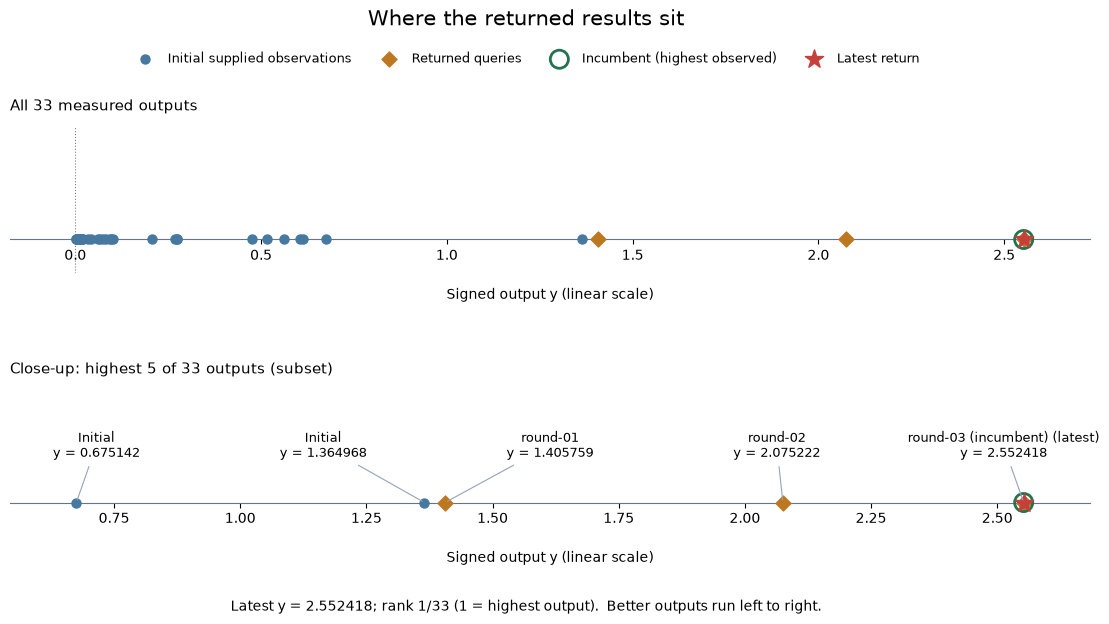

In [4]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

Both panels use the original signed output: moving right means a better score.
The full-range panel retains all 33 observations; the labelled close-up separates
the five highest values. No observation is removed from the data or calculations.

These are the outputs at the locations sampled so far. The later queries were
chosen using earlier evidence, so this view does not estimate the distribution
of scores throughout the input domain or establish the unknown global maximum.

## 3. Track progress across completed rounds

A high rank describes one result's position. A chronological view answers a
different question: which experiments actually improved the best score seen?
Compare each return with the best available **before that round**, in the
function's original output units.

In [5]:
running_best = float(initial["y"].max())
progress_rows = [{
    "source_round": 0, "stage": "Initial batch", "returned_y": np.nan,
    "best_y": running_best, "change_vs_prior_best": np.nan,
}]
for _, observation in returned.iterrows():
    value = float(observation["y"])
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({
        "source_round": int(observation["source_round"]),
        "stage": f"Round {int(observation['source_round'])}",
        "returned_y": value, "best_y": running_best,
        "change_vs_prior_best": change,
    })
progress = pd.DataFrame(progress_rows)
display(progress.set_index("stage")[[
    "returned_y", "best_y", "change_vs_prior_best",
]].rename(columns={
    "returned_y": "Returned output", "best_y": "Best observed after stage",
    "change_vs_prior_best": "Return minus previous best",
}).style.format(precision=6, na_rep="—"))

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,1.364968,—
Round 1,1.405759,1.405759,0.040791
Round 2,2.075222,2.075222,0.669463
Round 3,2.552418,2.552418,0.477196


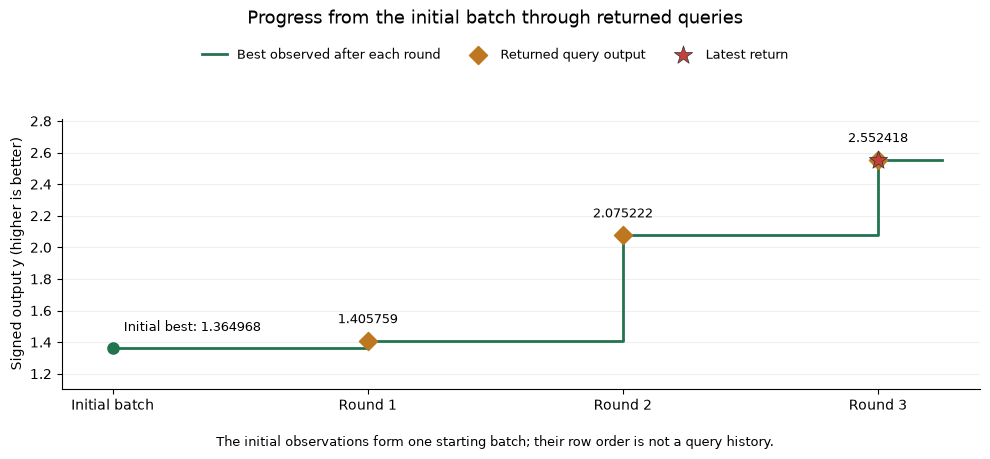

In [6]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

Each of rounds 1, 2 and 3 improved the incumbent. The best observed output
has risen from **1.364968** in the initial batch to **2.552418**, a gain of
**1.187449 output units**. The latest gain over round 2 is **0.477196**.

This is a clear record of improvement at the chosen inputs. It does not show
how close the current best is to the unknown global maximum, or establish that
this method would outperform another sequence. Three selected returns remain
a small amount of evidence in six dimensions.

## 4. Examine the strongest input combinations

Keep all six coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [7]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,x5,x6,y
observation_id,,,,,,,,,
round-03,1,3,0.018718,0.312926,0.370268,0.285721,0.308321,0.695670,2.552418
round-02,2,2,0.015118,0.386113,0.305380,0.283890,0.363300,0.714745,2.075222
round-01,3,1,0.057896,0.491672,0.247422,0.318118,0.420428,0.730970,1.405759
initial-007,4,0,0.057896,0.491672,0.247422,0.218118,0.420428,0.730970,1.364968
initial-025,5,0,0.881647,0.204450,0.414474,0.420385,0.264915,0.730660,0.675142


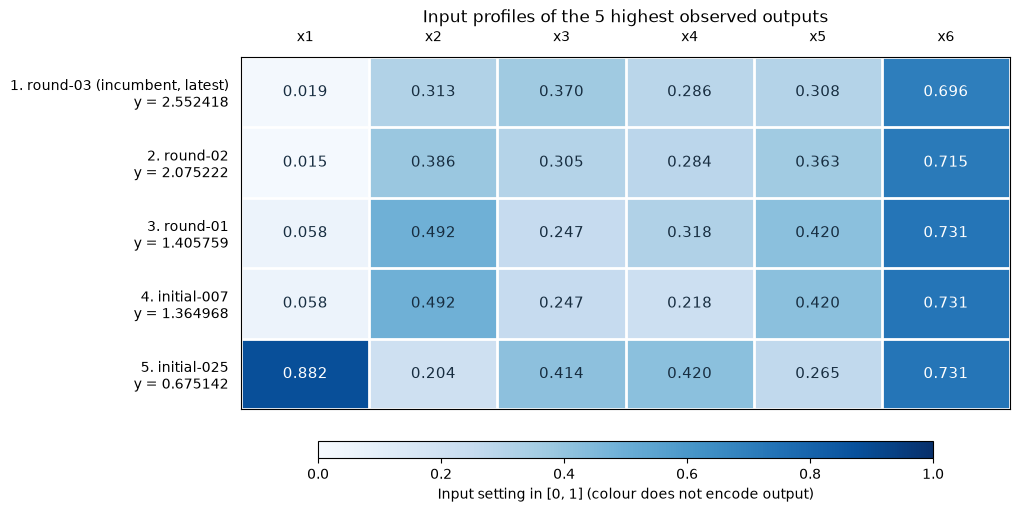

In [8]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

The three returned queries and the initial best all use **x1 below 0.06**
and **x6 between 0.695670 and 0.730970**. Across the returned queries, x2 and x5
decrease, x3 increases, and the measured output rises. The other coordinates
also change; this is a sequence of combinations, not a controlled experiment
on any one input.

The fifth-ranked observation has a very different x1 setting and a much lower
output. Rank alone hides that performance gap. The strongest combinations
justify continued interest in their region without excluding other regions or
claiming a direction of improvement for an individual coordinate.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [9]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full six-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.015118,0.018718,0.003600
x2,0.386113,0.312926,-0.073187
x3,0.305380,0.370268,0.064888
x4,0.283890,0.285721,0.001831
x5,0.363300,0.308321,-0.054979
x6,0.714745,0.695670,-0.019075


Previous best: round-02; y = 2.075222
Full six-input distance to previous best: 0.113884
Latest output minus previous best: +0.477196
Nearest earlier observation: round-02 (distance 0.113884)
Repeated full input combinations: 0


Round 2 is both the previous best and the nearest earlier observation to round 3.
Their full six-input distance is **0.113884**, and the latest output is
**0.477196 higher**. All six settings changed.

The improvement is observed, but this pair does not identify which changes
helped, whether further movement in the same direction would help, or how close
the region is to an optimum. No identical-input repeats are available to measure
repeat-evaluation noise.

## 5. Carry the evidence into model review

All three returned queries have improved the best observed output, giving
the model a new incumbent to learn from. Check whether the updated validation
and uncertainty support the next proposal, including whether it refines this
region or spends the next query on a different combination.

Continue in [model review and next query](model_predictions.ipynb) to examine:

- whether held-out GP predictions remain useful against the mean baseline,
  including their errors at the strongest observations;
- how predicted performance and uncertainty contribute to the next candidate;
- how predictions at the proposed location change under the tested noise
  assumptions, and whether exploration weights change the selected candidate,
  with ten query opportunities remaining.

The companion contains a saved Week 4 model run. Its proposed input was retained and submitted, confirmed on 20 October 2026.
Its validation and candidate comparisons use models, so they remain there.
Week 4 submission is confirmed in the [submission log](../../../submissions/README.md); its output is pending.

**Historical forecast check:** the [saved Week 3 model run](../Week_03/model_predictions.ipynb)
predicted **1.992333** for the submitted input. The measured return was
**2.552418**, or **0.560085 higher**. The saved forecast is
rounded to six decimals. This is a prediction made before the return, not a
model refitted with its answer; one forecast error does not establish calibration.